In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import odr
from scipy.stats import spearmanr, pearsonr

In [4]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.linalg import svd
from sklearn.metrics import mean_squared_error

In [5]:
from mpl_toolkits.mplot3d import Axes3D

In [6]:
sapply_df = pd.read_csv('D:\\Research\\Political_Bias_of_LLMs\\supplyValuesTest\\5_transform_to_csv\\sapply_scores_runs.csv')
sapply_df.head()

,model_name,run,right_score,auth_score,prog_score
0,anthropic_claude_4_sonnet,1,-1.67,1.00,3.75
1,anthropic_claude_4_sonnet,2,-2.00,1.00,4.06
2,anthropic_claude_4_sonnet,3,-1.67,1.67,3.75
3,anthropic_claude_4_sonnet,4,-2.00,1.67,3.44
4,anthropic_claude_4_sonnet,5,-1.67,1.67,3.75


In [7]:
# inverting the prog_score col to negate the scores
sapply_df['prog_score'] = -sapply_df['prog_score']
sapply_df.head()

,model_name,run,right_score,auth_score,prog_score
0,anthropic_claude_4_sonnet,1,-1.67,1.00,-3.75
1,anthropic_claude_4_sonnet,2,-2.00,1.00,-4.06
2,anthropic_claude_4_sonnet,3,-1.67,1.67,-3.75
3,anthropic_claude_4_sonnet,4,-2.00,1.67,-3.44
4,anthropic_claude_4_sonnet,5,-1.67,1.67,-3.75


In [8]:
# `right_score`, `auth_score`, `prog_score` all in [-10, 10]. lets make it [-3, 3]
sapply_df['right_score'] = sapply_df['right_score'] / 10 * 3
sapply_df['auth_score'] = sapply_df['auth_score'] / 10 * 3
sapply_df['prog_score'] = sapply_df['prog_score'] / 10 * 3
sapply_df.describe()

,run,right_score,auth_score,prog_score
count,270.000000,270.000000,270.000000,270.000000
mean,5.500000,-0.650222,0.212233,-1.088822
std,2.877615,0.420549,0.400761,0.453507
min,1.000000,-1.800000,-1.401000,-2.625000
25%,3.000000,-0.900000,0.000000,-1.500000
50%,5.500000,-0.600000,0.300000,-0.939000
75%,8.000000,-0.399000,0.501000,-0.750000
max,10.000000,0.699000,0.900000,-0.093000


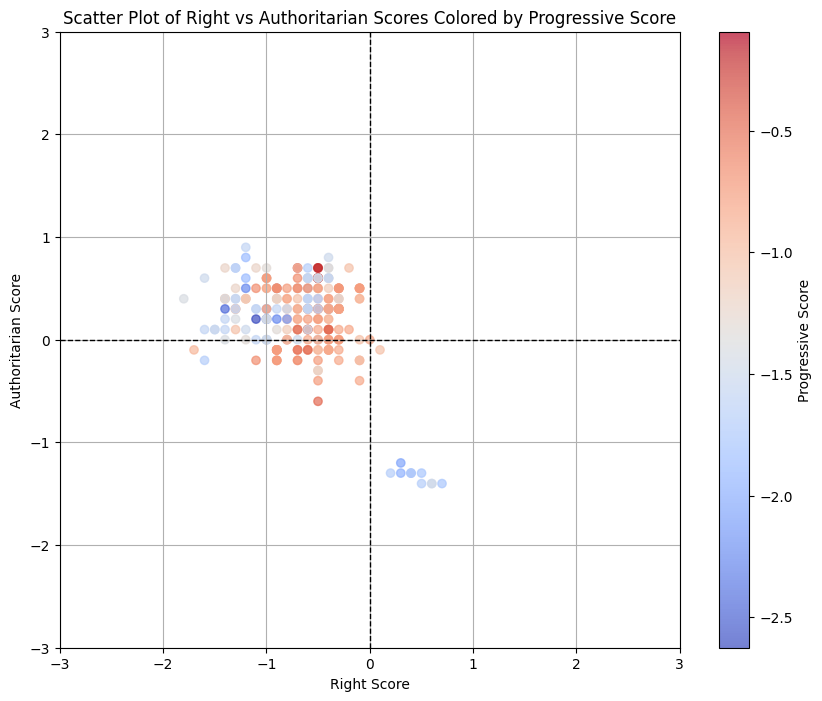

In [9]:
# visualizing the 3 scores where x => 'right_score', y => 'auth_score', color => 'prog_score'
# in 'prog_score' col, blue => -3, red => 3
# make sure the plot covers [-3, 3] in both x and y axis
# make sure axis lines are visible

plt.figure(figsize=(10, 8))
scatter = plt.scatter(sapply_df['right_score'], sapply_df['auth_score'], c=sapply_df['prog_score'], cmap='coolwarm', alpha=0.7)
plt.colorbar(scatter, label='Progressive Score')
plt.xlabel('Right Score')
plt.ylabel('Authoritarian Score')
plt.title('Scatter Plot of Right vs Authoritarian Scores Colored by Progressive Score')
plt.xlim([-3, 3])
plt.ylim([-3, 3])
plt.grid(True)
plt.axhline(0, color='black',linewidth=1, ls='--')
plt.axvline(0, color='black',linewidth=1, ls='--')

## Regression Line

Plane equation: 0.3080x + 0.5274y + -0.5579z + -0.5619 = 0
Orthogonal Regression MSE: 0.111531


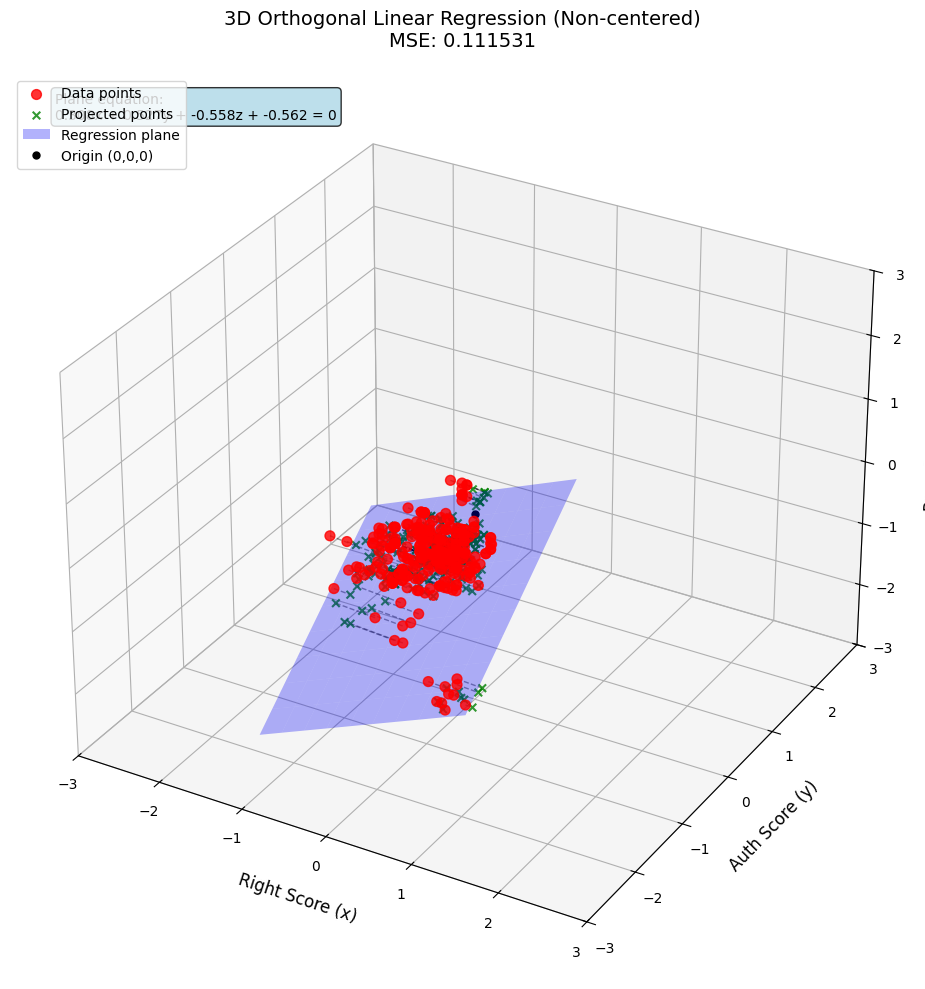


=== ORTHOGONAL LINEAR REGRESSION RESULTS (NON-CENTERED) ===
Normal vector: [0.308037, 0.527405, -0.557852]
Constant term: -0.561924
Mean Squared Error (perpendicular distance): 0.111531
Root Mean Squared Error: 0.333963
Average perpendicular distance: 0.267053
Distance from origin to plane: 0.679318


In [10]:
# Extract the data
x = sapply_df['right_score'].values
y = sapply_df['auth_score'].values
z = sapply_df['prog_score'].values

# Perform orthogonal regression WITHOUT centering
# We'll use the direct approach with SVD on the homogeneous coordinates
ones = np.ones_like(x)
A = np.column_stack([x, y, z, ones])

# Perform SVD
U, s, Vt = svd(A)
normal_vector = Vt[-1, :3]  # First three components are the normal vector
d = Vt[-1, 3]  # The constant term

# The plane equation: a*x + b*y + c*z + d = 0
a, b, c = normal_vector

print(f"Plane equation: {a:.4f}x + {b:.4f}y + {c:.4f}z + {d:.4f} = 0")

# Calculate predicted points (projections onto the plane)
# The projection of point (x0,y0,z0) onto plane ax+by+cz+d=0 is:
# (x0 - a*t, y0 - b*t, z0 - c*t) where t = (a*x0 + b*y0 + c*z0 + d)/(a^2 + b^2 + c^2)

t_values = (a*x + b*y + c*z + d) / (a**2 + b**2 + c**2)
x_pred = x - a * t_values
y_pred = y - b * t_values
z_pred = z - c * t_values

# Calculate MSE (perpendicular distance)
distances = np.abs(a*x + b*y + c*z + d) / np.sqrt(a**2 + b**2 + c**2)
mse = np.mean(distances**2)

print(f"Orthogonal Regression MSE: {mse:.6f}")

# Create a meshgrid for the plane
x_range = np.linspace(min(x), max(x), 10)
y_range = np.linspace(min(y), max(y), 10)
X, Y = np.meshgrid(x_range, y_range)

# Calculate Z values for the plane: a*X + b*Y + c*Z + d = 0
if c != 0:
    Z = (-d - a*X - b*Y) / c
else:
    # If c is 0, the plane is vertical - use average z for visualization
    Z = np.full_like(X, np.mean(z))

# Create the 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the original data points
scatter = ax.scatter(x, y, z, c='red', marker='o', s=50, alpha=0.8, label='Data points')

# Plot the predicted points (projections)
ax.scatter(x_pred, y_pred, z_pred, c='green', marker='x', s=30, alpha=0.8, label='Projected points')

# Plot the regression plane
plane = ax.plot_surface(X, Y, Z, alpha=0.3, color='blue', label='Regression plane')

# Add projection lines
for i in range(len(x)):
    ax.plot([x[i], x_pred[i]], [y[i], y_pred[i]], [z[i], z_pred[i]], 
            'k--', alpha=0.4, linewidth=1)

# Add labels and title
ax.set_xlabel('Right Score (x)', fontsize=12, labelpad=10)
ax.set_ylabel('Auth Score (y)', fontsize=12, labelpad=10)
ax.set_zlabel('Prog Score (z)', fontsize=12, labelpad=10)
ax.set_title('3D Orthogonal Linear Regression (Non-centered)\nMSE: {:.6f}'.format(mse), fontsize=14, pad=20)

# Set axis limits to [-3, 3] with origin visible
ax.set_xlim([-3, 3])
ax.set_ylim([-3, 3])
ax.set_zlim([-3, 3])

# Add grid and make sure origin is visible
ax.grid(True, alpha=0.3)
ax.plot([0], [0], [0], 'ko', markersize=5, label='Origin (0,0,0)')

# Create legend
ax.legend(loc='upper left')

# Add the equation as text
equation_text = f'Plane equation:\n{a:.3f}x + {b:.3f}y + {c:.3f}z + {d:.3f} = 0'
ax.text2D(0.05, 0.95, equation_text, transform=ax.transAxes, fontsize=10,
          bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.8))

plt.tight_layout()
plt.show()

# Print detailed results
print("\n=== ORTHOGONAL LINEAR REGRESSION RESULTS (NON-CENTERED) ===")
print(f"Normal vector: [{a:.6f}, {b:.6f}, {c:.6f}]")
print(f"Constant term: {d:.6f}")
print(f"Mean Squared Error (perpendicular distance): {mse:.6f}")
print(f"Root Mean Squared Error: {np.sqrt(mse):.6f}")
print(f"Average perpendicular distance: {np.mean(distances):.6f}")

# Additional analysis - show how the plane relates to the origin
origin_distance = np.abs(d) / np.sqrt(a**2 + b**2 + c**2)
print(f"Distance from origin to plane: {origin_distance:.6f}")

Verifying projected points lie on the plane:
Point 0: Plane equation value = 0.00000000 (should be close to 0)
Point 1: Plane equation value = 0.00000000 (should be close to 0)
Point 2: Plane equation value = -0.00000000 (should be close to 0)
Point 3: Plane equation value = 0.00000000 (should be close to 0)
Point 4: Plane equation value = -0.00000000 (should be close to 0)
Point 5: Plane equation value = -0.00000000 (should be close to 0)
Point 6: Plane equation value = -0.00000000 (should be close to 0)
Point 7: Plane equation value = 0.00000000 (should be close to 0)
Point 8: Plane equation value = 0.00000000 (should be close to 0)
Point 9: Plane equation value = 0.00000000 (should be close to 0)
Point 10: Plane equation value = 0.00000000 (should be close to 0)
Point 11: Plane equation value = 0.00000000 (should be close to 0)
Point 12: Plane equation value = 0.00000000 (should be close to 0)
Point 13: Plane equation value = 0.00000000 (should be close to 0)
Point 14: Plane equatio

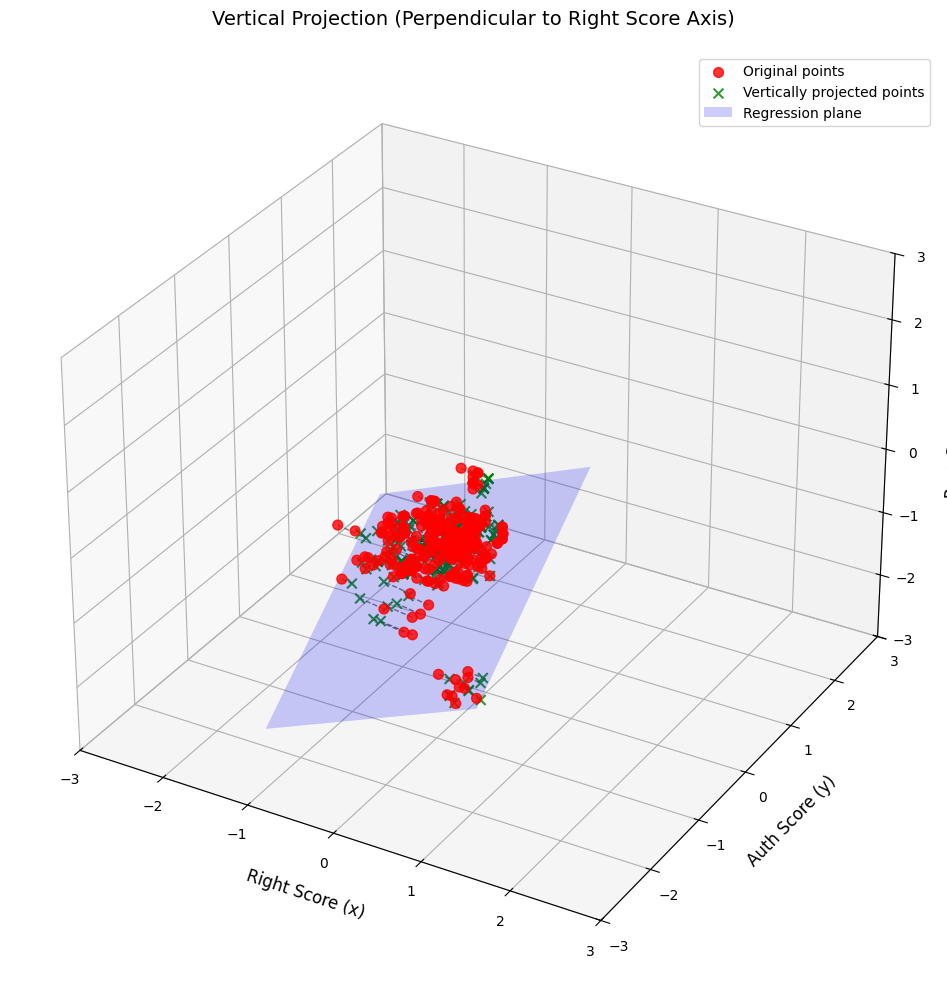


=== VERTICAL PROJECTION SUMMARY ===
Average vertical distance: 0.287749
Max vertical distance: 1.005113
Min vertical distance: 0.001539
Standard deviation of vertical distances: 0.216476

New dataframe shape: (270, 9)
Columns: ['model_name', 'run', 'right_score', 'auth_score', 'prog_score', 'right_score_proj', 'auth_score_proj', 'prog_score_proj', 'vertical_distance']


In [11]:
# Extract the data
x = sapply_df['right_score'].values
y = sapply_df['auth_score'].values
z = sapply_df['prog_score'].values

# Get the plane equation coefficients from previous orthogonal regression
# a*x + b*y + c*z + d = 0
# (You should have these values from the previous calculation)

# For vertical projection (perpendicular to right_score axis), we fix x and find y,z on the plane
# Given x = x0 (original x value), we solve for y and z in the plane equation:
# b*y + c*z = -a*x0 - d

# Create the new dataframe with projected points
sapply_projected = sapply_df.copy()

# Add columns for projected points
sapply_projected['right_score_proj'] = x  # x remains the same for vertical projection
sapply_projected['auth_score_proj'] = np.nan
sapply_projected['prog_score_proj'] = np.nan

# Calculate the projected points for each original point
for i in range(len(sapply_projected)):
    x0 = x[i]
    
    # We need to solve: b*y + c*z = -a*x0 - d
    # This is a line in the y-z plane. We'll find the point on this line closest to the original (y[i], z[i])
    
    # The line equation can be written as: [b, c] • [y, z]ᵀ = k, where k = -a*x0 - d
    
    if b != 0 or c != 0:
        # Find the point on the line that minimizes the distance to (y[i], z[i])
        # Using least squares projection
        
        # The line normal is [b, c], so we project (y[i], z[i]) onto the line
        k = -a * x0 - d
        
        # The projection formula for point (y0, z0) onto line b*y + c*z = k
        # is: [y_proj, z_proj] = [y0, z0] - (b*y0 + c*z0 - k) / (b² + c²) * [b, c]
        
        y0, z0 = y[i], z[i]
        numerator = b * y0 + c * z0 - k
        denominator = b**2 + c**2
        
        if denominator != 0:
            y_proj = y0 - (numerator / denominator) * b
            z_proj = z0 - (numerator / denominator) * c
        else:
            # If both b and c are 0, the plane is vertical to x-axis
            # In this case, any y,z satisfies the equation, so we keep original y,z
            y_proj, z_proj = y0, z0
            
        sapply_projected.loc[i, 'auth_score_proj'] = y_proj
        sapply_projected.loc[i, 'prog_score_proj'] = z_proj
    else:
        # If b = c = 0, the plane equation becomes a*x + d = 0
        # This means the plane is perpendicular to x-axis at x = -d/a
        # For vertical projection, we keep y,z unchanged
        sapply_projected.loc[i, 'auth_score_proj'] = y[i]
        sapply_projected.loc[i, 'prog_score_proj'] = z[i]

# Verify that all projected points lie on the plane
print("Verifying projected points lie on the plane:")
for i in range(len(sapply_projected)):
    x_proj = sapply_projected.loc[i, 'right_score_proj']
    y_proj = sapply_projected.loc[i, 'auth_score_proj']
    z_proj = sapply_projected.loc[i, 'prog_score_proj']
    
    plane_value = a*x_proj + b*y_proj + c*z_proj + d
    print(f"Point {i}: Plane equation value = {plane_value:.8f} (should be close to 0)")

# Calculate the vertical distances (difference in y and z coordinates)
sapply_projected['vertical_distance'] = np.sqrt(
    (sapply_projected['auth_score'] - sapply_projected['auth_score_proj'])**2 +
    (sapply_projected['prog_score'] - sapply_projected['prog_score_proj'])**2
)

# Display the new dataframe
print("\nFirst few rows of the projected dataframe:")
print(sapply_projected.head())

# Create a 3D plot to visualize the vertical projections
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot original points
ax.scatter(sapply_projected['right_score'], 
           sapply_projected['auth_score'], 
           sapply_projected['prog_score'], 
           c='red', marker='o', s=50, alpha=0.8, label='Original points')

# Plot projected points
ax.scatter(sapply_projected['right_score_proj'], 
           sapply_projected['auth_score_proj'], 
           sapply_projected['prog_score_proj'], 
           c='green', marker='x', s=50, alpha=0.8, label='Vertically projected points')

# Plot the regression plane (recreate it for visualization)
x_range = np.linspace(min(x), max(x), 10)
y_range = np.linspace(min(y), max(y), 10)
X, Y = np.meshgrid(x_range, y_range)

if c != 0:
    Z = (-d - a*X - b*Y) / c
else:
    Z = np.full_like(X, np.mean(z))

ax.plot_surface(X, Y, Z, alpha=0.2, color='blue', label='Regression plane')

# Draw vertical projection lines
for i in range(len(sapply_projected)):
    ax.plot([sapply_projected.loc[i, 'right_score'], sapply_projected.loc[i, 'right_score_proj']],
            [sapply_projected.loc[i, 'auth_score'], sapply_projected.loc[i, 'auth_score_proj']],
            [sapply_projected.loc[i, 'prog_score'], sapply_projected.loc[i, 'prog_score_proj']],
            'k--', alpha=0.5, linewidth=1)

# Add labels and title
ax.set_xlabel('Right Score (x)', fontsize=12, labelpad=10)
ax.set_ylabel('Auth Score (y)', fontsize=12, labelpad=10)
ax.set_zlabel('Prog Score (z)', fontsize=12, labelpad=10)
ax.set_title('Vertical Projection (Perpendicular to Right Score Axis)', fontsize=14, pad=20)

# Set axis limits
ax.set_xlim([-3, 3])
ax.set_ylim([-3, 3])
ax.set_zlim([-3, 3])

ax.legend()
plt.tight_layout()
plt.show()

# Print summary statistics
print("\n=== VERTICAL PROJECTION SUMMARY ===")
print(f"Average vertical distance: {sapply_projected['vertical_distance'].mean():.6f}")
print(f"Max vertical distance: {sapply_projected['vertical_distance'].max():.6f}")
print(f"Min vertical distance: {sapply_projected['vertical_distance'].min():.6f}")
print(f"Standard deviation of vertical distances: {sapply_projected['vertical_distance'].std():.6f}")

# Show the new dataframe structure
print(f"\nNew dataframe shape: {sapply_projected.shape}")
print("Columns:", list(sapply_projected.columns))

In [12]:
sapply_projected.head()

,model_name,run,right_score,auth_score,prog_score,right_score_proj,auth_score_proj,prog_score_proj,vertical_distance
0,anthropic_claude_4_sonnet,1,-0.501,0.300,-1.125,-0.501,0.237757,-1.059164,0.090601
1,anthropic_claude_4_sonnet,2,-0.600,0.300,-1.218,-0.600,0.218621,-1.131923,0.118456
2,anthropic_claude_4_sonnet,3,-0.501,0.501,-1.125,-0.501,0.343892,-0.958822,0.228687
3,anthropic_claude_4_sonnet,4,-0.600,0.501,-1.032,-0.600,0.417609,-0.943795,0.121384
4,anthropic_claude_4_sonnet,5,-0.501,0.501,-1.125,-0.501,0.343892,-0.958822,0.228687


First few rows with calculated scores:
                  model_name  run  right_score_proj  auth_score_proj  \
0  anthropic_claude_4_sonnet    1            -0.501         0.237757   
1  anthropic_claude_4_sonnet    2            -0.600         0.218621   
2  anthropic_claude_4_sonnet    3            -0.501         0.343892   
3  anthropic_claude_4_sonnet    4            -0.600         0.417609   
4  anthropic_claude_4_sonnet    5            -0.501         0.343892   

   prog_score_proj  distance_from_origin     score  
0        -1.059164              1.195558 -1.195558  
1        -1.131923              1.299632 -1.299632  
2        -0.958822              1.135166 -1.135166  
3        -0.943795              1.193795 -1.193795  
4        -0.958822              1.135166 -1.135166  

=== SCORE SUMMARY STATISTICS ===
Score range: [-2.4800, 2.4627]
Mean score: -1.2364
Median score: -1.2801
Standard deviation: 0.8011

Score distribution:
Positive scores: 11 (4.1%)
Negative scores: 258 (95.6%)

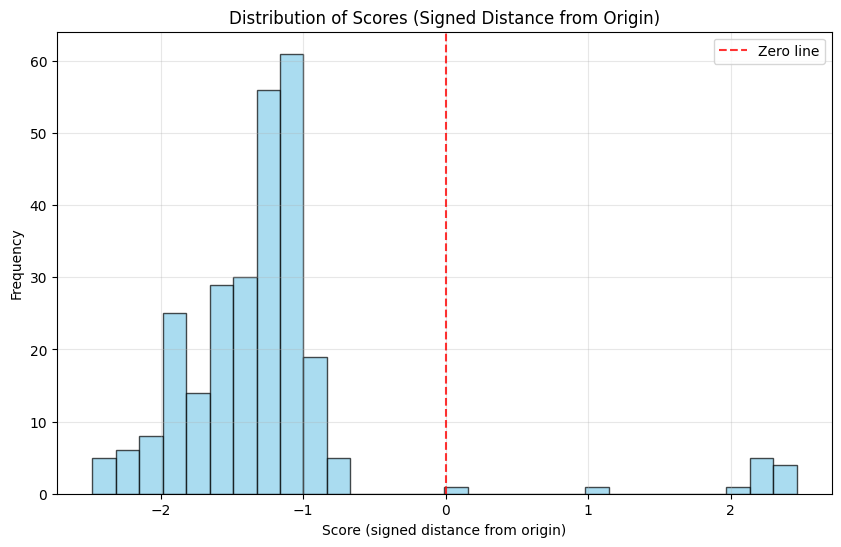


Correlation between original right_score and new score: 0.8348


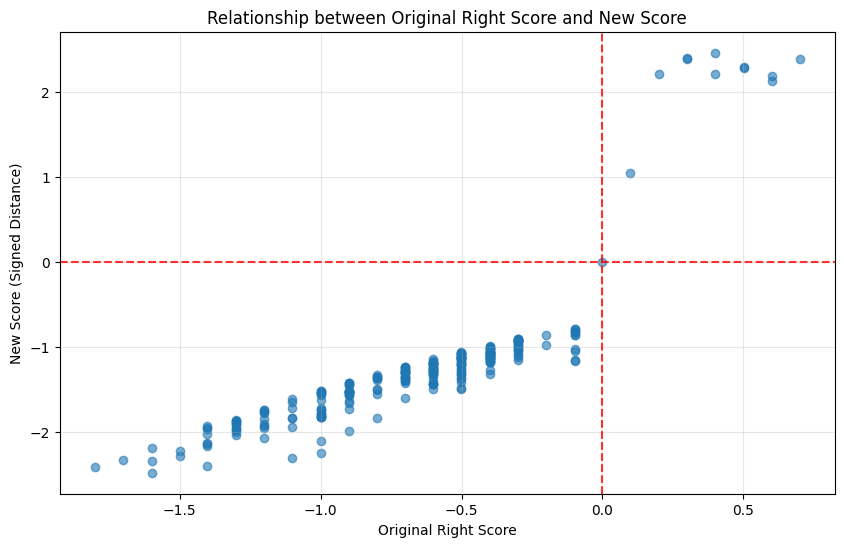


=== VERIFICATION EXAMPLES ===
A few examples showing how the score is calculated:
Point 0:
  Projected coordinates: (-0.501, 0.238, -1.059)
  Distance from origin: 1.196
  Sign of right_score_proj: -1
  Final score: -1.196

Point 1:
  Projected coordinates: (-0.600, 0.219, -1.132)
  Distance from origin: 1.300
  Sign of right_score_proj: -1
  Final score: -1.300

Point 2:
  Projected coordinates: (-0.501, 0.344, -0.959)
  Distance from origin: 1.135
  Sign of right_score_proj: -1
  Final score: -1.135

Point 3:
  Projected coordinates: (-0.600, 0.418, -0.944)
  Distance from origin: 1.194
  Sign of right_score_proj: -1
  Final score: -1.194

Point 4:
  Projected coordinates: (-0.501, 0.344, -0.959)
  Distance from origin: 1.135
  Sign of right_score_proj: -1
  Final score: -1.135



In [13]:
# Calculate the Euclidean distance from origin (0,0,0) for each projected point
sapply_projected['distance_from_origin'] = np.sqrt(
    sapply_projected['right_score_proj']**2 +
    sapply_projected['auth_score_proj']**2 +
    sapply_projected['prog_score_proj']**2
)

# Assign the sign of right_score_proj to the distance
sapply_projected['score'] = np.sign(sapply_projected['right_score_proj']) * sapply_projected['distance_from_origin']

# Display the results
print("First few rows with calculated scores:")
print(sapply_projected[['model_name', 'run', 'right_score_proj', 'auth_score_proj', 'prog_score_proj', 'distance_from_origin', 'score']].head())

# Print summary statistics
print("\n=== SCORE SUMMARY STATISTICS ===")
print(f"Score range: [{sapply_projected['score'].min():.4f}, {sapply_projected['score'].max():.4f}]")
print(f"Mean score: {sapply_projected['score'].mean():.4f}")
print(f"Median score: {sapply_projected['score'].median():.4f}")
print(f"Standard deviation: {sapply_projected['score'].std():.4f}")

# Count positive, negative, and zero scores
positive_scores = (sapply_projected['score'] > 0).sum()
negative_scores = (sapply_projected['score'] < 0).sum()
zero_scores = (sapply_projected['score'] == 0).sum()

print(f"\nScore distribution:")
print(f"Positive scores: {positive_scores} ({positive_scores/len(sapply_projected)*100:.1f}%)")
print(f"Negative scores: {negative_scores} ({negative_scores/len(sapply_projected)*100:.1f}%)")
print(f"Zero scores: {zero_scores} ({zero_scores/len(sapply_projected)*100:.1f}%)")

# Create a histogram of the scores
plt.figure(figsize=(10, 6))
plt.hist(sapply_projected['score'], bins=30, alpha=0.7, color='skyblue', edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', alpha=0.8, label='Zero line')
plt.xlabel('Score (signed distance from origin)')
plt.ylabel('Frequency')
plt.title('Distribution of Scores (Signed Distance from Origin)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Show correlation between original right_score and the new score
correlation = np.corrcoef(sapply_projected['right_score'], sapply_projected['score'])[0, 1]
print(f"\nCorrelation between original right_score and new score: {correlation:.4f}")

# Create a scatter plot to show the relationship
plt.figure(figsize=(10, 6))
plt.scatter(sapply_projected['right_score'], sapply_projected['score'], alpha=0.6)
plt.xlabel('Original Right Score')
plt.ylabel('New Score (Signed Distance)')
plt.title('Relationship between Original Right Score and New Score')
plt.grid(alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.8)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.8)
plt.show()

# Show some examples to verify the calculation
print("\n=== VERIFICATION EXAMPLES ===")
print("A few examples showing how the score is calculated:")
for i in range(min(5, len(sapply_projected))):
    row = sapply_projected.iloc[i]
    print(f"Point {i}:")
    print(f"  Projected coordinates: ({row['right_score_proj']:.3f}, {row['auth_score_proj']:.3f}, {row['prog_score_proj']:.3f})")
    print(f"  Distance from origin: {row['distance_from_origin']:.3f}")
    print(f"  Sign of right_score_proj: {np.sign(row['right_score_proj']):.0f}")
    print(f"  Final score: {row['score']:.3f}")
    print()

In [15]:
sapply_projected.describe()

,run,right_score,auth_score,prog_score,right_score_proj,auth_score_proj,prog_score_proj,vertical_distance,distance_from_origin,score
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000
mean,5.500000,-0.650222,0.212233,-1.088822,-0.650222,0.250608,-1.129413,0.287749,1.417833,-1.236437
std,2.877615,0.420549,0.400761,0.453507,0.420549,0.363070,0.320984,0.216476,0.402123,0.801078
min,1.000000,-1.800000,-1.401000,-2.625000,-1.800000,-1.323421,-2.038169,0.001539,0.792567,-2.479950
25%,3.000000,-0.900000,0.000000,-1.500000,-0.900000,0.147227,-1.288890,0.119149,1.118098,-1.551510
50%,5.500000,-0.600000,0.300000,-0.939000,-0.600000,0.287487,-1.072339,0.241244,1.303166,-1.280074
75%,8.000000,-0.399000,0.501000,-0.750000,-0.399000,0.431489,-0.933434,0.414138,1.659542,-1.089077
max,10.000000,0.699000,0.900000,-0.093000,0.699000,0.970287,-0.418217,1.005113,2.479950,2.462677


Original score range: [-2.4800, 2.4627]
Theoretical maximum range: [-5.1962, 5.1962] = [-5.1962, 5.1962]
Scaled score range: [-1.4318, 1.4218]


C:\Users\sakha\AppData\Local\Temp\ipykernel_27232\3531929467.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot(boxplot_data, labels=['Original', 'Scaled'])


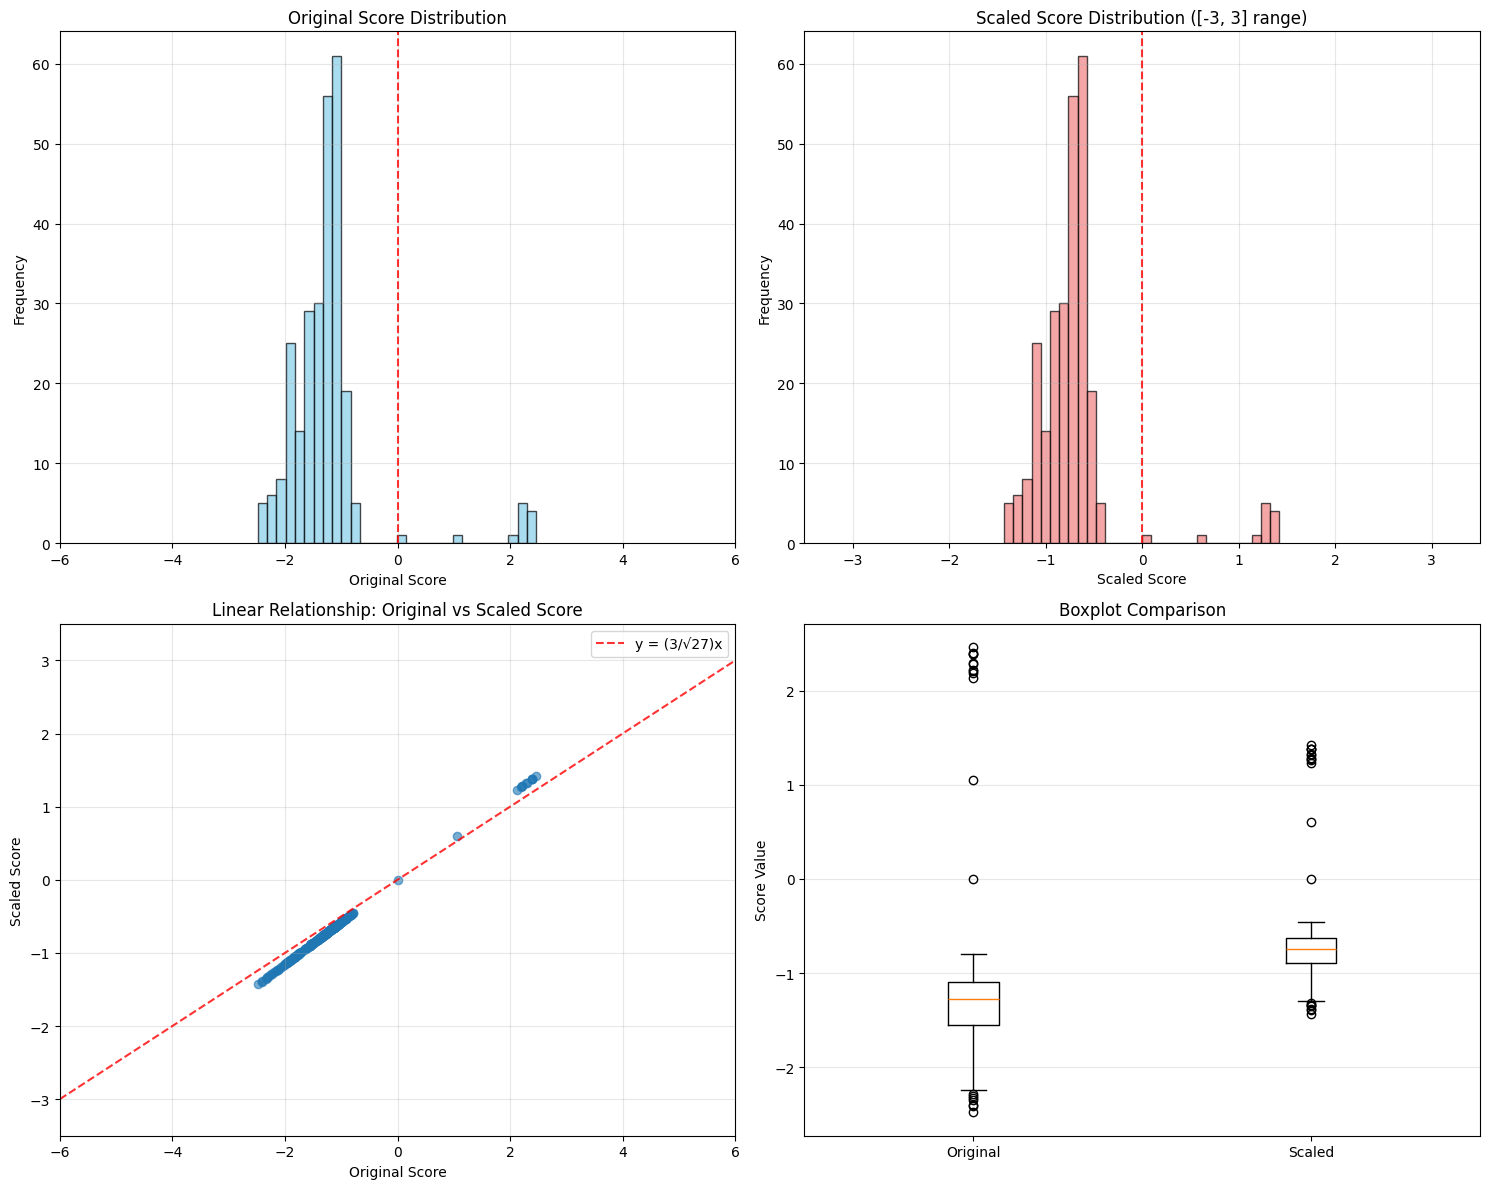

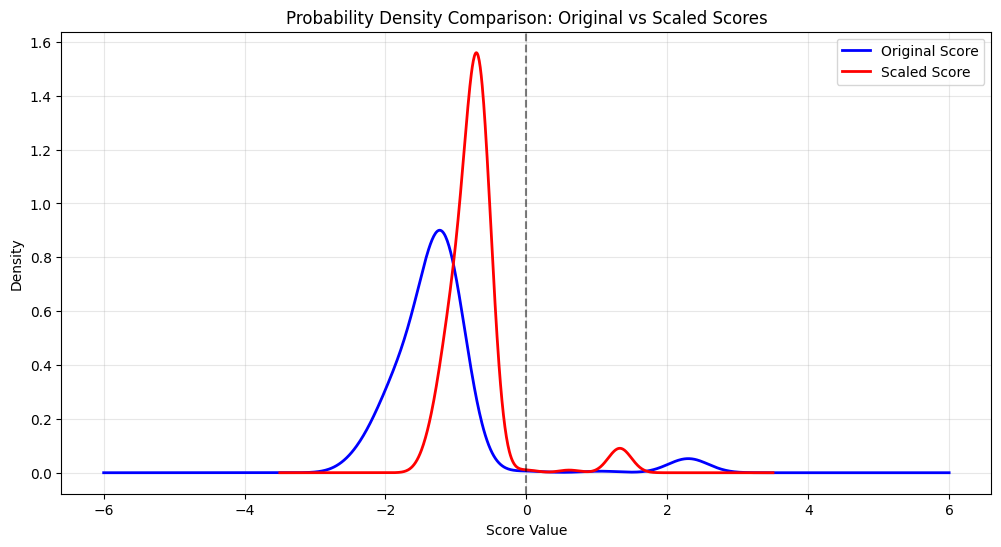


=== STATISTICAL COMPARISON ===
Original Score Statistics:
  Mean: -1.2364
  Std: 0.8011
  Median: -1.2801
  Skewness: 3.1247
  Kurtosis: 11.9438

Scaled Score Statistics:
  Mean: -0.7139
  Std: 0.4625
  Median: -0.7391
  Skewness: 3.1247
  Kurtosis: 11.9438

Expected scaling factor: 0.577350
Actual average scaling factor: 0.577350
Correlation between original and scaled scores: 1.00000000
Spearman rank correlation: 1.00000000

=== SCALING EXAMPLES ===
A few examples showing the scaling transformation:
Point 0:
  Original score: -1.1956
  Scaled score: -0.6903
  Scaling factor: 0.577350 (should be 0.577350)

Point 1:
  Original score: -1.2996
  Scaled score: -0.7503
  Scaling factor: 0.577350 (should be 0.577350)

Point 2:
  Original score: -1.1352
  Scaled score: -0.6554
  Scaling factor: 0.577350 (should be 0.577350)

Point 3:
  Original score: -1.1938
  Scaled score: -0.6892
  Scaling factor: 0.577350 (should be 0.577350)

Point 4:
  Original score: -1.1352
  Scaled score: -0.6554
 

In [16]:
# Calculate the current range of scores
current_min = sapply_projected['score'].min()
current_max = sapply_projected['score'].max()
current_range = current_max - current_min

print(f"Original score range: [{current_min:.4f}, {current_max:.4f}]")
print(f"Theoretical maximum range: [-{np.sqrt(27):.4f}, {np.sqrt(27):.4f}] = [-5.1962, 5.1962]")

# Scale the score to [-3, 3] range
# We'll use min-max scaling centered around 0
sapply_projected['score_scaled'] = 3 * (sapply_projected['score'] / np.sqrt(27))

# Verify the scaled range
scaled_min = sapply_projected['score_scaled'].min()
scaled_max = sapply_projected['score_scaled'].max()
print(f"Scaled score range: [{scaled_min:.4f}, {scaled_max:.4f}]")

# Create comparison plots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Histogram comparison
axes[0, 0].hist(sapply_projected['score'], bins=30, alpha=0.7, color='skyblue', edgecolor='black')
axes[0, 0].axvline(x=0, color='red', linestyle='--', alpha=0.8)
axes[0, 0].set_xlabel('Original Score')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Original Score Distribution')
axes[0, 0].grid(alpha=0.3)
axes[0, 0].set_xlim([-6, 6])

axes[0, 1].hist(sapply_projected['score_scaled'], bins=30, alpha=0.7, color='lightcoral', edgecolor='black')
axes[0, 1].axvline(x=0, color='red', linestyle='--', alpha=0.8)
axes[0, 1].set_xlabel('Scaled Score')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Scaled Score Distribution ([-3, 3] range)')
axes[0, 1].grid(alpha=0.3)
axes[0, 1].set_xlim([-3.5, 3.5])

# Scatter plot showing the linear relationship
axes[1, 0].scatter(sapply_projected['score'], sapply_projected['score_scaled'], alpha=0.6)
axes[1, 0].plot([-6, 6], [-3, 3], 'r--', alpha=0.8, label='y = (3/√27)x')
axes[1, 0].set_xlabel('Original Score')
axes[1, 0].set_ylabel('Scaled Score')
axes[1, 0].set_title('Linear Relationship: Original vs Scaled Score')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_xlim([-6, 6])
axes[1, 0].set_ylim([-3.5, 3.5])

# Boxplot comparison
boxplot_data = [sapply_projected['score'], sapply_projected['score_scaled']]
axes[1, 1].boxplot(boxplot_data, labels=['Original', 'Scaled'])
axes[1, 1].set_ylabel('Score Value')
axes[1, 1].set_title('Boxplot Comparison')
axes[1, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Create density plots for better comparison
plt.figure(figsize=(12, 6))

# Kernel Density Estimation plots
from scipy import stats

# Original score KDE
kde_original = stats.gaussian_kde(sapply_projected['score'])
x_vals = np.linspace(-6, 6, 1000)
y_original = kde_original(x_vals)

# Scaled score KDE (should have identical shape)
kde_scaled = stats.gaussian_kde(sapply_projected['score_scaled'])
x_vals_scaled = np.linspace(-3.5, 3.5, 1000)
y_scaled = kde_scaled(x_vals_scaled)

plt.plot(x_vals, y_original, 'b-', linewidth=2, label='Original Score')
plt.plot(x_vals_scaled, y_scaled, 'r-', linewidth=2, label='Scaled Score')
plt.axvline(x=0, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Score Value')
plt.ylabel('Density')
plt.title('Probability Density Comparison: Original vs Scaled Scores')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Print statistical comparison
print("\n=== STATISTICAL COMPARISON ===")
print("Original Score Statistics:")
print(f"  Mean: {sapply_projected['score'].mean():.4f}")
print(f"  Std: {sapply_projected['score'].std():.4f}")
print(f"  Median: {sapply_projected['score'].median():.4f}")
print(f"  Skewness: {sapply_projected['score'].skew():.4f}")
print(f"  Kurtosis: {sapply_projected['score'].kurtosis():.4f}")

print("\nScaled Score Statistics:")
print(f"  Mean: {sapply_projected['score_scaled'].mean():.4f}")
print(f"  Std: {sapply_projected['score_scaled'].std():.4f}")
print(f"  Median: {sapply_projected['score_scaled'].median():.4f}")
print(f"  Skewness: {sapply_projected['score_scaled'].skew():.4f}")
print(f"  Kurtosis: {sapply_projected['score_scaled'].kurtosis():.4f}")

# Verify the scaling factor
expected_scaling_factor = 3 / np.sqrt(27)
actual_scaling_factor = (sapply_projected['score_scaled'] / sapply_projected['score']).mean()
print(f"\nExpected scaling factor: {expected_scaling_factor:.6f}")
print(f"Actual average scaling factor: {actual_scaling_factor:.6f}")

# Show that the distribution shape is preserved
correlation = np.corrcoef(sapply_projected['score'], sapply_projected['score_scaled'])[0, 1]
print(f"Correlation between original and scaled scores: {correlation:.8f}")

# Check if ranks are preserved
from scipy.stats import spearmanr
spearman_corr, p_value = spearmanr(sapply_projected['score'], sapply_projected['score_scaled'])
print(f"Spearman rank correlation: {spearman_corr:.8f}")

# Show some examples
print("\n=== SCALING EXAMPLES ===")
print("A few examples showing the scaling transformation:")
for i in range(min(5, len(sapply_projected))):
    row = sapply_projected.iloc[i]
    print(f"Point {i}:")
    print(f"  Original score: {row['score']:.4f}")
    print(f"  Scaled score: {row['score_scaled']:.4f}")
    print(f"  Scaling factor: {row['score_scaled']/row['score']:.6f} (should be {3/np.sqrt(27):.6f})")
    print()

In [17]:
sapply_projected.head()

,model_name,run,right_score,auth_score,prog_score,right_score_proj,auth_score_proj,prog_score_proj,vertical_distance,distance_from_origin,score,score_scaled
0,anthropic_claude_4_sonnet,1,-0.501,0.300,-1.125,-0.501,0.237757,-1.059164,0.090601,1.195558,-1.195558,-0.690256
1,anthropic_claude_4_sonnet,2,-0.600,0.300,-1.218,-0.600,0.218621,-1.131923,0.118456,1.299632,-1.299632,-0.750343
2,anthropic_claude_4_sonnet,3,-0.501,0.501,-1.125,-0.501,0.343892,-0.958822,0.228687,1.135166,-1.135166,-0.655389
3,anthropic_claude_4_sonnet,4,-0.600,0.501,-1.032,-0.600,0.417609,-0.943795,0.121384,1.193795,-1.193795,-0.689238
4,anthropic_claude_4_sonnet,5,-0.501,0.501,-1.125,-0.501,0.343892,-0.958822,0.228687,1.135166,-1.135166,-0.655389


In [18]:
sapply_projected.to_csv('sapply_final_oneD_scores.csv', index=False)

In [20]:
# Calculate summary statistics for each model
summary_df = sapply_projected.groupby('model_name')['score_scaled'].agg(
    score_mean=('mean'),
    score_SD=('std'),
    score_MAD=lambda x: np.mean(np.abs(x - np.mean(x)))
).reset_index()

# Round the values for better readability
summary_df['score_mean'] = summary_df['score_mean'].round(4)
summary_df['score_SD'] = summary_df['score_SD'].round(4)
summary_df['score_MAD'] = summary_df['score_MAD'].round(4)

# Sort by score_mean (most negative to most positive)
summary_df = summary_df.sort_values('score_mean')
summary_df

,model_name,score_mean,score_SD,score_MAD
21,openai_gpt_5_mini,-1.2697,0.0821,0.0616
4,google_gemini_2_5_pro,-1.1939,0.1132,0.0915
23,openai_gpt_oss_120b,-1.1139,0.1691,0.1216
3,google_gemini_2_5_flash,-1.0558,0.0894,0.0641
17,openai_gpt_4_1_mini,-1.0317,0.0443,0.0321
19,openai_gpt_4o,-0.9925,0.0983,0.0866
22,openai_gpt_5_nano,-0.9098,0.1037,0.0719
8,meta_llama_4_maverick_instruct,-0.8902,0.0083,0.0072
1,cohere_command_r_08_2024,-0.8496,0.1163,0.0843
15,moonshotai_kimi_k2_instruct,-0.8169,0.1131,0.0891


In [21]:
summary_df.to_csv('sapply_model_summary_statistics.csv', index=False)

In [3]:
the_df = pd.read_csv('eightValues_final_oneD_scores.csv')
the_df.head()

,model_name,run,equality,globe,liberty,progress,equality_projection,globe_projection,liberty_projection,progress_projection,absolute_score,score_scaled
0,pred_[1]_anthropic_claude_4_sonnet,1,-0.846,-0.564,-0.612,-0.804,-0.846,-0.515780,-0.350000,-0.823508,-1.335070,-0.667535
1,pred_[2]_anthropic_claude_4_sonnet,2,-0.882,-0.636,-0.588,-0.834,-0.882,-0.534513,-0.356357,-0.838104,-1.375877,-0.687938
2,pred_[3]_anthropic_claude_4_sonnet,3,-0.732,-0.636,-0.588,-0.780,-0.732,-0.456458,-0.329871,-0.777289,-1.207133,-0.603567
3,pred_[4]_anthropic_claude_4_sonnet,4,-0.846,-0.564,-0.540,-0.858,-0.846,-0.515780,-0.350000,-0.823508,-1.335070,-0.667535
4,pred_[5]_anthropic_claude_4_sonnet,5,-0.882,-0.636,-0.588,-0.834,-0.882,-0.534513,-0.356357,-0.838104,-1.375877,-0.687938


In [ ]:
# Calculate summary statistics for each model
summary_df = sapply_projected.groupby('model_name')['score_scaled'].agg(
    score_mean=('mean'),
    score_SD=('std'),
    score_MAD=lambda x: np.mean(np.abs(x - np.mean(x)))
).reset_index()

# Round the values for better readability
summary_df['score_mean'] = summary_df['score_mean'].round(4)
summary_df['score_SD'] = summary_df['score_SD'].round(4)
summary_df['score_MAD'] = summary_df['score_MAD'].round(4)

# Sort by score_mean (most negative to most positive)
summary_df = summary_df.sort_values('score_mean')
summary_df

Number of runs per model:
1    270
Name: count, dtype: int64


,model_name,score_mean,score_SD,score_MAD
0,pred_[8]_openai_gpt_oss_120b,-1.2281,0.0,0.0
1,pred_[4]_openai_gpt_5,-1.1392,0.0,0.0
2,pred_[3]_openai_gpt_5,-1.1392,0.0,0.0
3,pred_[9]_openai_gpt_4_1,-1.1392,0.0,0.0
4,pred_[8]_google_gemini_2_5_flash,-1.1143,0.0,0.0
...,...,...,...,...
265,pred_[10]_x_ai_grok_4,0.2421,0.0,0.0
266,pred_[7]_x_ai_grok_4,0.2496,0.0,0.0
267,pred_[8]_x_ai_grok_4,0.2546,0.0,0.0
268,pred_[5]_x_ai_grok_4,0.2674,0.0,0.0
